# ECE 285 Homework 2 — Generating Paintings with a GAN

This notebook

1. implements a GAN (a DCGAN generator and a spectrally-normalised DCGAN discriminator),
2. trains it **on the GPU** on the WikiArt painting dataset in `./archive` (~81k paintings, 27 styles),
3. uses the trained generator to generate new painting images,
4. evaluates the generated images with the **Inception Score (IS)** and **Fréchet Inception Distance (FID)**, using the
   PyTorch-Ignite code from `2021-08-11-GAN-evaluation-using-FID-and-IS.ipynb`
   ([blog post](https://pytorch-ignite.ai/blog/gan-evaluation-with-fid-and-is/)).

Every figure and number needed for the report (hyperparameters, loss curves, IS/FID, sample images) is also saved to `./outputs/`.

**Run modes** (set in the configuration cell):

* `SMOKE_TEST = True` – 6,400 images and 2 epochs, a few minutes end-to-end, to check that everything runs.
* `TRAIN = False` – skip training, reload `outputs/checkpoint.pt` and only redo the plots and evaluation.

**Expected runtime on an RTX 5070 Ti:** about 35 min in total, estimated from the smoke test: 1–2 min to build the 64×64 image cache (first run only), ~13 s per training epoch (~22 min for 100 epochs), ~20 s per FID/IS evaluation during training (every 5 epochs, ~7 min in total) and ~3 min for the final evaluation.

## 1. Setup

In [1]:
# torch must be imported BEFORE numpy/matplotlib: in this miniconda environment, importing numpy first makes
# torch fail with "OSError: [WinError 127] ... torch\lib\shm.dll" (conflicting DLLs). If you hit that error,
# restart the kernel and run this cell first.
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.utils as vutils
from torch.nn.utils.parametrizations import spectral_norm

import os
import json
import time
import copy
import random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
import PIL.Image as Image

import ignite
from ignite.engine import Engine, Events
from ignite.metrics import FID, InceptionScore

Image.MAX_IMAGE_PIXELS = None  # some WikiArt scans are very large; they are trusted local files

print(*map(lambda m: ": ".join((m.__name__, m.__version__)), (torch, torchvision, ignite)), sep="\n")

torch: 2.11.0+cu128
torchvision: 0.26.0+cu128
ignite: 0.5.5


In [2]:
# Train on the GPU with CUDA. Stop here rather than silently falling back to a CPU run that would take days.
assert torch.cuda.is_available(), "No CUDA GPU found: this notebook is meant to train on the GPU (RTX 5070 Ti)."
device = torch.device("cuda")
props = torch.cuda.get_device_properties(device)
print(f"Device: {props.name} ({props.total_memory / 2**30:.1f} GiB) | CUDA {torch.version.cuda} | cuDNN {torch.backends.cudnn.version()}")

torch.backends.cudnn.benchmark = True  # input sizes never change, so let cuDNN pick the fastest conv kernels

Device: NVIDIA GeForce RTX 5070 Ti (15.9 GiB) | CUDA 12.8 | cuDNN 91900


## 2. Hyperparameters

In [3]:
# ---------------- paths ----------------
DATA_ROOT = Path("./archive")   # WikiArt, one sub-folder per style
CACHE_DIR = Path("./cache")     # pre-resized uint8 image cache (built once, ~1 GB)
OUT_DIR = Path("./outputs")     # figures, metrics and checkpoint for the report

# ---------------- run mode ----------------
SMOKE_TEST = False  # True: small subset + 2 epochs, only to check the pipeline end-to-end
TRAIN = True        # False: skip training and load OUT_DIR / "checkpoint.pt"

# ---------------- GAN hyperparameters ----------------
SEED = 999
IMAGE_SIZE = 64          # DCGAN resolution, as in the reference notebook
BATCH_SIZE = 128
LATENT_DIM = 100         # dimension of z
NGF, NDF = 64, 64        # base channel widths of G and D
NUM_EPOCHS = 100
LR_G, LR_D = 2e-4, 2e-4
BETAS = (0.5, 0.999)     # Adam betas from the DCGAN paper
EMA_DECAY = 0.999        # exponential moving average of G's weights, used for sampling and evaluation
HFLIP = True             # random horizontal flips (data augmentation)
MAX_IMAGES = None        # None = use every image in DATA_ROOT

# ---------------- evaluation ----------------
EVAL_EVERY = 5               # compute FID / IS every N epochs during training
EVAL_SAMPLES = 3000          # images per FID / IS evaluation during training (as in the reference)
FINAL_EVAL_SAMPLES = 10000   # images for the final reported numbers
EVAL_BATCH_SIZE = 100

if SMOKE_TEST:
    MAX_IMAGES, NUM_EPOCHS = 6400, 2
    EVAL_EVERY, EVAL_SAMPLES, FINAL_EVAL_SAMPLES = 1, 500, 1000
    OUT_DIR = OUT_DIR.with_name(OUT_DIR.name + "_smoke")

CACHE_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
ignite.utils.manual_seed(SEED)

hparams = {
    "image_size": IMAGE_SIZE, "batch_size": BATCH_SIZE, "latent_dim": LATENT_DIM, "ngf": NGF, "ndf": NDF,
    "epochs": NUM_EPOCHS, "optimizer": "Adam", "lr_G": LR_G, "lr_D": LR_D, "adam_betas": list(BETAS),
    "loss": "non-saturating BCE (BCEWithLogitsLoss)", "G_normalization": "BatchNorm",
    "D_normalization": "spectral norm", "ema_decay": EMA_DECAY, "hflip": HFLIP, "seed": SEED,
    "eval_samples_during_training": EVAL_SAMPLES, "final_eval_samples": FINAL_EVAL_SAMPLES,
}
with open(OUT_DIR / "hparams.json", "w") as f:
    json.dump(hparams, f, indent=2)
for k, v in hparams.items():
    print(f"{k:>30}: {v}")

                    image_size: 64
                    batch_size: 128
                    latent_dim: 100
                           ngf: 64
                           ndf: 64
                        epochs: 100
                     optimizer: Adam
                          lr_G: 0.0002
                          lr_D: 0.0002
                    adam_betas: [0.5, 0.999]
                          loss: non-saturating BCE (BCEWithLogitsLoss)
               G_normalization: BatchNorm
               D_normalization: spectral norm
                     ema_decay: 0.999
                         hflip: True
                          seed: 999
  eval_samples_during_training: 3000
            final_eval_samples: 10000


## 3. Painting dataset (WikiArt)

The images in `./archive` are full-resolution scans (often 1–2k pixels per side). Decoding ~81k large JPEGs every epoch
would make the CPU, not the GPU, the bottleneck. So every image goes through the reference notebook's transform
(`Resize(64)` + `CenterCrop(64)`) **once**. The result is cached as a single `uint8` array of shape `(N, 3, 64, 64)` (~1 GB)
in `./cache/`. Later runs load the cache in seconds.

In [5]:
RESIZE = transforms.Compose([transforms.Resize(IMAGE_SIZE), transforms.CenterCrop(IMAGE_SIZE)])


def list_images(root):
    return sorted(p for p in root.rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png"})


def load_and_resize(path):
    """Reference transform (Resize + CenterCrop) -> uint8 array (3, H, W); None if the file can't be read."""
    try:
        with Image.open(path) as img:
            img.draft("RGB", (2 * IMAGE_SIZE, 2 * IMAGE_SIZE))  # fast JPEG DCT downscaling, keeps >= 2x headroom
            img = RESIZE(img.convert("RGB"))
            return np.asarray(img, dtype=np.uint8).transpose(2, 0, 1)
    except Exception as e:
        print(f"  skipping {path}: {e}")
        return None


def build_cache(root, max_images=None):
    files = list_images(root)
    if max_images is not None:  # random subset across all styles (used by the smoke test)
        random.Random(SEED).shuffle(files)
        files = sorted(files[:max_images])
    tag = f"wikiart_{IMAGE_SIZE}" + (f"_n{max_images}" if max_images else "")
    cache_file = CACHE_DIR / f"{tag}.npy"
    if cache_file.exists():
        data = np.load(cache_file)
        print(f"Loaded {len(data)} images from {cache_file}")
        return data

    print(f"Resizing {len(files)} images to {IMAGE_SIZE}x{IMAGE_SIZE} (one-time) ...")
    t0 = time.time()
    data = np.empty((len(files), 3, IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8)
    keep = np.zeros(len(files), dtype=bool)
    with ThreadPoolExecutor(max_workers=os.cpu_count()) as pool:  # PIL releases the GIL while decoding/resizing
        for i, arr in enumerate(pool.map(load_and_resize, files)):
            if arr is not None:
                data[i], keep[i] = arr, True
            if (i + 1) % 10000 == 0:
                print(f"  {i + 1}/{len(files)} ({time.time() - t0:.0f}s)")
    if not keep.all():
        data = data[keep]
    tmp = cache_file.with_suffix(".tmp")
    with open(tmp, "wb") as f:
        np.save(f, data)
    os.replace(tmp, cache_file)  # only a complete cache file ever gets the final name
    print(f"Cached {len(data)} images ({(~keep).sum()} skipped) in {time.time() - t0:.0f}s -> {cache_file}")
    return data

In [6]:
images_u8 = build_cache(DATA_ROOT, MAX_IMAGES)
num_images = len(images_u8)
print(f"{num_images} paintings, array {images_u8.shape}, {images_u8.nbytes / 2**30:.2f} GiB")

Resizing 81444 images to 64x64 (one-time) ...
  10000/81444 (10s)
  20000/81444 (18s)
  30000/81444 (28s)
  40000/81444 (38s)
  50000/81444 (47s)
  60000/81444 (56s)
  70000/81444 (65s)
  80000/81444 (75s)
Cached 81444 images (0 skipped) in 79s -> cache\wikiart_64.npy
81444 paintings, array (81444, 3, 64, 64), 0.93 GiB


### Loading batches on the GPU

The whole `uint8` dataset (~1 GB) is copied into GPU memory once. Each batch is sliced, converted to `float` in
`[-1, 1]` (the reference's `Normalize((0.5,)*3, (0.5,)*3)`) and randomly flipped, all on the GPU. No CPU worker
processes are needed, which also sidesteps the Windows multiprocessing problems of `DataLoader(num_workers>0)` inside Jupyter.

The reference used `Subset(train_dataset, torch.arange(3000))` as the real image set for FID. Here `ImageFolder` is sorted
by style, so that would be 3,000 *Abstract Expressionism* paintings only. A **random** subset is used instead.

In [7]:
class GPUImageLoader:
    """Minimal DataLoader replacement for a uint8 image tensor that already lives on the GPU.

    Yields 1-tuples `(images,)` with images in [-1, 1], matching the `data[0]` convention of the reference code.
    """

    def __init__(self, images_u8, batch_size, shuffle=True, drop_last=True, hflip=False):
        self.data = images_u8
        self.batch_size, self.shuffle, self.drop_last, self.hflip = batch_size, shuffle, drop_last, hflip

    def __len__(self):
        n, b = len(self.data), self.batch_size
        return n // b if self.drop_last else -(-n // b)

    def __iter__(self):
        n, dev = len(self.data), self.data.device
        order = torch.randperm(n, device=dev) if self.shuffle else torch.arange(n, device=dev)
        for i in range(len(self)):
            x = self.data[order[i * self.batch_size:(i + 1) * self.batch_size]].float().div_(127.5).sub_(1.0)
            if self.hflip:
                flip = torch.rand(x.size(0), 1, 1, 1, device=dev) < 0.5
                x = torch.where(flip, x.flip(3), x)
            yield (x,)


all_images = torch.from_numpy(images_u8).to(device)
del images_u8  # free ~1 GB of host RAM

perm = torch.randperm(num_images, generator=torch.Generator().manual_seed(SEED))
eval_real_a = all_images[perm[:FINAL_EVAL_SAMPLES]]                          # real images FID compares against
eval_real_b = all_images[perm[FINAL_EVAL_SAMPLES:2 * FINAL_EVAL_SAMPLES]]    # disjoint real set (real-vs-real baseline)

train_dataloader = GPUImageLoader(all_images, BATCH_SIZE, shuffle=True, drop_last=True, hflip=HFLIP)
test_dataloader = GPUImageLoader(eval_real_a[:EVAL_SAMPLES], EVAL_BATCH_SIZE, shuffle=False, drop_last=False)
final_dataloader = GPUImageLoader(eval_real_a, EVAL_BATCH_SIZE, shuffle=False, drop_last=False)
print(f"train: {len(train_dataloader)} iterations/epoch | FID/IS during training: {EVAL_SAMPLES} real images | "
      f"final: {FINAL_EVAL_SAMPLES}")

train: 636 iterations/epoch | FID/IS during training: 3000 real images | final: 10000


In [8]:
# Plot style for the report figures: quiet axes and grid, one fixed colour per series.
COLOR_G, COLOR_D = "#2a78d6", "#eb6834"        # generator = blue, discriminator = orange
COLOR_REAL, COLOR_FAKE = "#1baf7a", "#eda100"  # D(x) on real images = aqua, D(G(z)) on generated images = yellow
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "figure.facecolor": "white",
    "font.size": 9, "axes.titlesize": 10, "axes.titlelocation": "left", "axes.labelcolor": INK, "text.color": INK,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "legend.frameon": False, "lines.linewidth": 1.6,
})


def to_uint8(images):
    """float images in [-1, 1] -> uint8 CPU tensor (compact storage for snapshots)."""
    return ((images.detach().float().clamp(-1, 1) + 1) * 127.5).round().to(torch.uint8).cpu()


def grid_image(images, nrow=8, padding=2):
    """Batch of images (float in [-1, 1] or uint8) -> H x W x 3 uint8 numpy grid with white padding."""
    x = images.detach().cpu()
    x = x.float() / 255.0 if x.dtype == torch.uint8 else (x.float().clamp(-1, 1) + 1) / 2
    grid = vutils.make_grid(x, nrow=nrow, padding=padding, pad_value=1.0)
    return (grid.permute(1, 2, 0).numpy() * 255).round().astype(np.uint8)


def save_figure(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(OUT_DIR / f"{name}.{ext}")


def smooth(x, y, window):
    """Moving average; returns x and y aligned to the end of each window."""
    y = np.asarray(y, dtype=float)
    window = max(1, min(window, len(y)))
    return np.asarray(x)[window - 1:], np.convolve(y, np.ones(window) / window, mode="valid")


def end_labels(ax, items, min_gap=0.05):
    """Direct labels at the right end of several lines, nudged apart (min_gap = fraction of the y-range)."""
    lo, hi = ax.get_ylim()
    gap = min_gap * (hi - lo)
    ends = sorted((y[-1], x[-1], text) for x, y, text in items)
    prev = -np.inf
    for y_end, x_end, text in ends:
        y_pos = max(y_end, prev + gap)
        prev = y_pos
        ax.annotate(text, (x_end, y_pos), xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=8)


def label_point(ax, x, y, text, above=True):
    """Label one marker, with the text pointing toward the middle of the plot so it never hits the axes."""
    lo, hi = ax.get_xlim()
    inward = 1 if x < (lo + hi) / 2 else -1
    ax.annotate(text, (x, y), xytext=(6 * inward, 9 if above else -11), textcoords="offset points",
                ha="left" if inward > 0 else "right", va="center", color=INK, fontsize=8)


def legend_below(ax):
    ax.legend(loc="upper left", bbox_to_anchor=(0, -0.2), ncol=2)

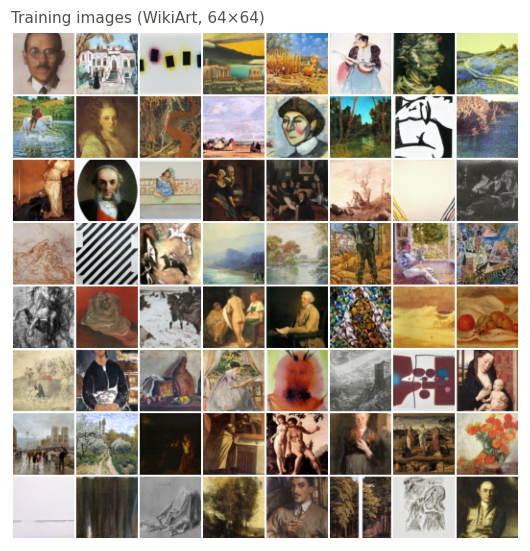

In [9]:
real_batch = next(iter(train_dataloader))[0]
fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(grid_image(real_batch[:64]))
ax.set_title("Training images (WikiArt, 64×64)")
ax.axis("off")
plt.show()

## 4. GAN model

### Generator

The generator is the DCGAN generator from the reference notebook (`Generator3x64x64`). It maps a latent vector
`z ~ N(0, I)` of size 100 to a 3×64×64 image in `[-1, 1]` through four stride-2 transposed convolutions with BatchNorm and ReLU.

In [10]:
def initialize_fn(m):
    """DCGAN weight init (reference notebook): conv weights ~ N(0, 0.02), BatchNorm weights ~ N(1, 0.02)."""
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


class Generator(nn.Module):
    """DCGAN generator: z (latent_dim x 1 x 1) -> image (3 x 64 x 64) in [-1, 1]."""

    def __init__(self, latent_dim, ngf=64):
        super().__init__()
        self.model = nn.Sequential(
            nn.ConvTranspose2d(latent_dim, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # state size. (ngf*8) x 4 x 4
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. (ngf*4) x 8 x 8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. (ngf*2) x 16 x 16
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # state size. ngf x 32 x 32
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False),
            nn.Tanh(),
            # final state size. 3 x 64 x 64
        )

    def forward(self, x):
        return self.model(x)

### Discriminator

The discriminator keeps the reference DCGAN layout (four stride-2 convolutions with LeakyReLU(0.2)), with two changes:

* **Spectral normalization** ([Miyato et al., 2018](https://arxiv.org/abs/1802.05957)) on every convolution replaces
  BatchNorm. WikiArt is much more diverse than CelebA (portraits, landscapes, abstract art, ukiyo-e, ...), and a plain DCGAN
  discriminator easily overpowers the generator on it. Spectral norm bounds the discriminator's Lipschitz constant, which
  keeps the gradients reaching G informative and training stable.
* **No final `Sigmoid`**: D outputs a logit and the loss is `BCEWithLogitsLoss`. This is the same objective as the
  reference's `Sigmoid` + `BCELoss`, but numerically stable.

In [11]:
def sn_conv(in_ch, out_ch, kernel, stride, padding):
    conv = nn.Conv2d(in_ch, out_ch, kernel, stride, padding)
    initialize_fn(conv)  # init the raw weight *before* wrapping it with spectral norm
    nn.init.zeros_(conv.bias)
    return spectral_norm(conv)


class Discriminator(nn.Module):
    """DCGAN discriminator with spectral norm: image (3 x 64 x 64) -> real/fake logit."""

    def __init__(self, ndf=64):
        super().__init__()
        self.model = nn.Sequential(
            # input is 3 x 64 x 64
            sn_conv(3, ndf, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. ndf x 32 x 32
            sn_conv(ndf, ndf * 2, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*2) x 16 x 16
            sn_conv(ndf * 2, ndf * 4, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*4) x 8 x 8
            sn_conv(ndf * 4, ndf * 8, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*8) x 4 x 4
            sn_conv(ndf * 8, 1, 4, 1, 0),
            # output: 1 x 1 x 1 logit
        )

    def forward(self, x):
        return self.model(x)

### Generator EMA

An exponential moving average of the generator weights, $\theta_{EMA} \leftarrow \beta\,\theta_{EMA} + (1-\beta)\,\theta_G$
with $\beta = 0.999$, is kept during training. It smooths out the oscillations of adversarial training, and samples
from it usually look cleaner and score better on FID.

The generator has BatchNorm, so its running statistics have to match the weights they are used with. G's own running
statistics belong to G's current weights, not the averaged ones. Copying them to the EMA model makes it output nearly
constant images (a bug the smoke test caught). Instead, the EMA model's BatchNorm statistics are re-estimated from its
own outputs before every use, the "standing statistics" of [Brock et al., 2019](https://arxiv.org/abs/1809.11096).
Section 10 reports FID/IS for both the raw and the EMA generator.

In [12]:
class EMA:
    """Exponential moving average of a generator's weights.

    Access the averaged model through `.generator`: it re-estimates the BatchNorm running statistics for the averaged
    weights ("standing statistics") whenever the weights changed since the last access.
    """

    def __init__(self, model, decay, bn_batches=20, bn_batch_size=256):
        self.decay, self.bn_batches, self.bn_batch_size = decay, bn_batches, bn_batch_size
        self.model = copy.deepcopy(model).eval().requires_grad_(False)
        self.stale = True

    @torch.no_grad()
    def update(self, model):
        for p_ema, p in zip(self.model.parameters(), model.parameters()):
            p_ema.lerp_(p, 1.0 - self.decay)
        self.stale = True

    @torch.no_grad()
    def recompute_bn_stats(self):
        bns = [m for m in self.model.modules() if isinstance(m, nn.modules.batchnorm._BatchNorm)]
        for bn in bns:
            bn.reset_running_stats()
            bn.momentum = None  # cumulative average over the batches below
        rng = torch.Generator(device=device).manual_seed(0)  # separate RNG: does not disturb training randomness
        self.model.train()
        for _ in range(self.bn_batches):
            self.model(torch.randn(self.bn_batch_size, LATENT_DIM, 1, 1, device=device, generator=rng))
        self.model.eval()
        self.stale = False

    @property
    def generator(self):
        if self.stale:
            self.recompute_bn_stats()
        return self.model


netG = Generator(LATENT_DIM, NGF).to(device)
netG.apply(initialize_fn)
netD = Discriminator(NDF).to(device)
netG_ema = EMA(netG, EMA_DECAY)  # starts from the same initial weights as netG

n_params = lambda m: sum(p.numel() for p in m.parameters())
with torch.no_grad():
    netG.eval()
    netD.eval()
    z = torch.randn(2, LATENT_DIM, 1, 1, device=device)
    x = netG(z)
    print(f"Generator:     z {tuple(z.shape[1:])} -> image {tuple(x.shape[1:])}  | {n_params(netG) / 1e6:.2f}M parameters")
    print(f"Discriminator: image {tuple(x.shape[1:])} -> logit {tuple(netD(x).shape[1:])}  | {n_params(netD) / 1e6:.2f}M parameters")
print(netG)
print(netD)

Generator:     z (100, 1, 1) -> image (3, 64, 64)  | 3.58M parameters
Discriminator: image (3, 64, 64) -> logit (1, 1, 1)  | 2.76M parameters
Generator(
  (model): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (

## 5. Loss and optimizers

* Loss: binary cross-entropy (as in the reference), applied to logits with `BCEWithLogitsLoss`. The generator uses the
  *non-saturating* loss: it maximises $\log D(G(z))$ instead of minimising $\log(1 - D(G(z)))$.
* Optimizers: two separate Adam optimizers, `lr = 2e-4`, `betas = (0.5, 0.999)` (DCGAN paper / reference).
* A fixed batch of 64 latent vectors is used to visualise the generator's progress during training.

In [13]:
criterion = nn.BCEWithLogitsLoss()

fixed_noise = torch.randn(64, LATENT_DIM, 1, 1, generator=torch.Generator().manual_seed(SEED)).to(device)

optimizerD = optim.Adam(netD.parameters(), lr=LR_D, betas=BETAS)
optimizerG = optim.Adam(netG.parameters(), lr=LR_G, betas=BETAS)


@torch.no_grad()
def sample(generator, noise):
    generator.eval()
    return generator(noise)


@torch.no_grad()
def generate(generator, n, batch_size=500):
    """n random samples from `generator`, in [-1, 1]."""
    generator.eval()
    return torch.cat([generator(torch.randn(min(batch_size, n - i), LATENT_DIM, 1, 1, device=device))
                      for i in range(0, n, batch_size)])

## 6. Training loop (PyTorch-Ignite)

As in the reference, training uses an Ignite `Engine` that runs `training_step` on every batch, with handlers attached to
its events. One step:

1. **Update D**: maximise $\log D(x) + \log(1 - D(G(z)))$ on one real batch and one generated batch.
2. **Update G**: maximise $\log D(G(z))$ with the updated D.
3. Update the generator EMA.

In [14]:
real_label = 1.0
fake_label = 0.0


def training_step(engine, data):
    netG.train()
    netD.train()

    ############################
    # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
    ############################
    optimizerD.zero_grad(set_to_none=True)
    real = data[0]
    b_size = real.size(0)
    label_real = torch.full((b_size,), real_label, device=device)
    label_fake = torch.full((b_size,), fake_label, device=device)
    # all-real batch
    output1 = netD(real).view(-1)
    errD_real = criterion(output1, label_real)
    # all-fake batch
    noise = torch.randn(b_size, LATENT_DIM, 1, 1, device=device)
    fake = netG(noise)
    output2 = netD(fake.detach()).view(-1)
    errD_fake = criterion(output2, label_fake)
    errD = errD_real + errD_fake
    errD.backward()
    optimizerD.step()

    ############################
    # (2) Update G network: maximize log(D(G(z)))
    ############################
    optimizerG.zero_grad(set_to_none=True)
    output3 = netD(fake).view(-1)  # D was just updated, so run the fake batch through it again
    errG = criterion(output3, label_real)  # fake labels are real for the generator cost
    errG.backward()
    optimizerG.step()

    netG_ema.update(netG)

    # a single GPU -> CPU sync per iteration instead of five .item() calls
    stats = torch.stack([errG, errD, output1.sigmoid().mean(), output2.sigmoid().mean(), output3.sigmoid().mean()])
    return dict(zip(("Loss_G", "Loss_D", "D_x", "D_G_z1", "D_G_z2"), stats.detach().tolist()))


trainer = Engine(training_step)

history = {k: [] for k in ("Loss_G", "Loss_D", "D_x", "D_G_z1", "D_G_z2", "epoch_time", "eval_epoch", "fid", "is")}
snapshots = []  # (epoch, uint8 samples of the EMA generator on fixed_noise)


@trainer.on(Events.ITERATION_COMPLETED)
def store_losses(engine):
    for k, v in engine.state.output.items():
        history[k].append(v)


@trainer.on(Events.EPOCH_STARTED)
def start_epoch_timer(engine):
    engine.state.epoch_start = time.time()

## 7. Evaluation metrics: FID and IS

This follows the reference notebook. `ignite.metrics.FID` and `ignite.metrics.InceptionScore` are attached to an
evaluation `Engine`. Its step function generates a fake batch and takes a real batch, then resizes both to 299×299 with
PIL bilinear interpolation, which InceptionV3 needs.

* **IS** (higher is better) uses InceptionV3's class probabilities on the *generated* images. It rewards confident and diverse predictions.
* **FID** (lower is better) is the Fréchet distance between Gaussians fitted to InceptionV3 pool features of real and generated images.

**One fix to the reference code:** the reference passes images in `[-1, 1]` straight to `ToPILImage`, which multiplies by
255 and casts to `uint8`, so every negative value wraps around and corrupts the colours. Here `interpolate` maps images to
`[0, 1]` first.

**Scale of the numbers:** this code feeds `[0, 1]` images (not ImageNet-normalised ones) to torchvision's InceptionV3.
That compresses the feature statistics, so its FID values are far below 1 instead of the usual tens to hundreds. The
reference notebook itself reports FID 0.075 → 0.016 on CelebA. The values are only comparable with other runs of this
same code, not with numbers from papers that use `pytorch-fid`. To give them context, section 10 also computes FID
between two disjoint sets of *real* paintings (the floor) and the IS of real paintings (the reference level).

In [15]:
def interpolate(batch):
    # From the reference notebook, plus [-1, 1] -> [0, 1] before ToPILImage (see the note above).
    batch = (batch.detach().float().cpu() * 0.5 + 0.5).clamp_(0, 1)
    arr = []
    for img in batch:
        pil_img = transforms.ToPILImage()(img)
        resized_img = pil_img.resize((299, 299), Image.BILINEAR)
        arr.append(transforms.ToTensor()(resized_img))
    return torch.stack(arr)


fid_metric = FID(device=device)
is_metric = InceptionScore(device=device, output_transform=lambda x: x[0])

# Function n -> batch of n "fake" images in [-1, 1]. Swapping it lets one evaluator score several generators.
eval_source = {"sample_fn": None}


def evaluation_step(engine, batch):
    with torch.no_grad():
        real = batch[0]
        fake = eval_source["sample_fn"](real.size(0))
        return interpolate(fake), interpolate(real)


evaluator = Engine(evaluation_step)
fid_metric.attach(evaluator, "fid")
is_metric.attach(evaluator, "is")


def evaluate(sample_fn, real_loader):
    """FID(sample_fn's images vs real_loader) and IS(sample_fn's images), with the ignite evaluator."""
    eval_source["sample_fn"] = sample_fn
    evaluator.run(real_loader, max_epochs=1)
    return float(evaluator.state.metrics["fid"]), float(evaluator.state.metrics["is"])


def generator_sampler(generator):
    def sample_fn(n):
        generator.eval()
        return generator(torch.randn(n, LATENT_DIM, 1, 1, device=device))
    return sample_fn


def real_sampler(images_u8):
    """Serves consecutive batches of real images as the 'fake' side (real-vs-real baseline)."""
    pos = {"i": 0}

    def sample_fn(n):
        i = pos["i"]
        pos["i"] = i + n
        return images_u8[i:i + n].float().div(127.5).sub(1.0)
    return sample_fn

### Per-epoch logging, evaluation and checkpoints

At the end of every epoch the handler below prints the average losses and stores samples from the fixed noise. Every
`EVAL_EVERY` epochs it also computes FID/IS on `EVAL_SAMPLES` images with the EMA generator and saves
`outputs/checkpoint.pt`. The checkpoint holds the models, optimizers and full history, so an interrupted run still keeps its results.

In [16]:
CKPT_PATH = OUT_DIR / "checkpoint.pt"


def save_checkpoint(epoch):
    state = {
        "epoch": epoch, "hparams": hparams, "history": history, "snapshots": snapshots,
        "netG": netG.state_dict(), "netD": netD.state_dict(), "netG_ema": netG_ema.model.state_dict(),
        "optimizerG": optimizerG.state_dict(), "optimizerD": optimizerD.state_dict(),
    }
    tmp = CKPT_PATH.with_suffix(".tmp")
    torch.save(state, tmp)
    os.replace(tmp, CKPT_PATH)  # an interrupted save never overwrites the last good checkpoint


def load_checkpoint(path=CKPT_PATH):
    state = torch.load(path, map_location=device)
    netG.load_state_dict(state["netG"])
    netD.load_state_dict(state["netD"])
    netG_ema.model.load_state_dict(state["netG_ema"])
    netG_ema.stale = True
    optimizerG.load_state_dict(state["optimizerG"])
    optimizerD.load_state_dict(state["optimizerD"])
    history.clear()
    history.update(state["history"])
    snapshots[:] = state["snapshots"]
    return state["epoch"]


@trainer.on(Events.EPOCH_COMPLETED)
def log_training_results(engine):
    epoch, n, max_epochs = engine.state.epoch, engine.state.epoch_length, engine.state.max_epochs
    history["epoch_time"].append(time.time() - engine.state.epoch_start)
    avg = {k: float(np.mean(history[k][-n:])) for k in ("Loss_D", "Loss_G", "D_x", "D_G_z1")}
    snapshots.append((epoch, to_uint8(sample(netG_ema.generator, fixed_noise))))
    msg = (f"Epoch [{epoch:3d}/{max_epochs}] {history['epoch_time'][-1]:5.1f}s | Loss_D {avg['Loss_D']:.3f}  "
           f"Loss_G {avg['Loss_G']:.3f} | D(x) {avg['D_x']:.3f}  D(G(z)) {avg['D_G_z1']:.3f}")
    if epoch % EVAL_EVERY == 0 or epoch == max_epochs:
        t0 = time.time()
        fid_score, is_score = evaluate(generator_sampler(netG_ema.generator), test_dataloader)
        history["eval_epoch"].append(epoch)
        history["fid"].append(fid_score)
        history["is"].append(is_score)
        save_checkpoint(epoch)
        msg += f" | FID {fid_score:.4f}  IS {is_score:.3f} ({time.time() - t0:.0f}s)"
    print(msg, flush=True)

## 8. Train

The reference launched training with `idist.Parallel(backend="nccl")`. NCCL is not available on Windows, and this is a
single-GPU run, so the trainer is run directly. Everything (data, G, D, Inception) is on the CUDA device.

In [17]:
if TRAIN:
    print(f"Training on {torch.cuda.get_device_name(device)}: {NUM_EPOCHS} epochs x {len(train_dataloader)} iterations")
    t_start = time.time()
    trainer.run(train_dataloader, max_epochs=NUM_EPOCHS)
    print(f"Training finished in {(time.time() - t_start) / 60:.1f} min "
          f"(peak GPU memory {torch.cuda.max_memory_allocated() / 2**30:.1f} GiB)")
else:
    last_epoch = load_checkpoint()
    print(f"Loaded checkpoint from epoch {last_epoch}: {CKPT_PATH}")

Training on NVIDIA GeForce RTX 5070 Ti: 100 epochs x 636 iterations
Epoch [  1/100]  17.4s | Loss_D 1.130  Loss_G 1.179 | D(x) 0.613  D(G(z)) 0.402
Epoch [  2/100]  12.8s | Loss_D 1.278  Loss_G 0.980 | D(x) 0.542  D(G(z)) 0.450
Epoch [  3/100]  12.8s | Loss_D 1.281  Loss_G 0.953 | D(x) 0.537  D(G(z)) 0.452
Epoch [  4/100]  12.5s | Loss_D 1.222  Loss_G 1.104 | D(x) 0.560  D(G(z)) 0.434
Epoch [  5/100]  12.6s | Loss_D 1.199  Loss_G 1.165 | D(x) 0.572  D(G(z)) 0.429 | FID 0.0879  IS 1.400 (35s)
Epoch [  6/100]  12.5s | Loss_D 1.159  Loss_G 1.323 | D(x) 0.582  D(G(z)) 0.413
Epoch [  7/100]  12.8s | Loss_D 1.137  Loss_G 1.346 | D(x) 0.594  D(G(z)) 0.407
Epoch [  8/100]  12.7s | Loss_D 1.120  Loss_G 1.318 | D(x) 0.597  D(G(z)) 0.406
Epoch [  9/100]  12.8s | Loss_D 1.077  Loss_G 1.369 | D(x) 0.609  D(G(z)) 0.391
Epoch [ 10/100]  12.6s | Loss_D 1.041  Loss_G 1.425 | D(x) 0.625  D(G(z)) 0.377 | FID 0.1149  IS 1.609 (14s)
Epoch [ 11/100]  12.6s | Loss_D 1.045  Loss_G 1.404 | D(x) 0.619  D(G(z)) 

## 9. Results

### Training loss curves

Faint lines are per-iteration values. Solid lines are moving averages over half an epoch.

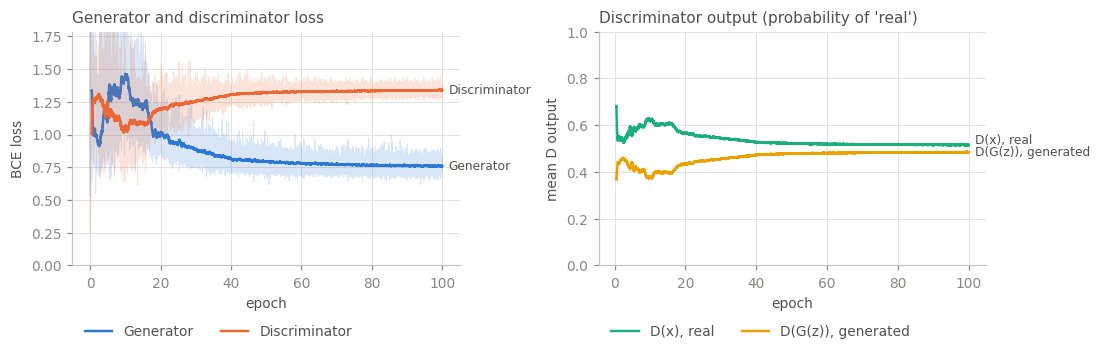

In [18]:
iters_per_epoch = len(train_dataloader)
x_epoch = np.arange(1, len(history["Loss_G"]) + 1) / iters_per_epoch
window = max(1, iters_per_epoch // 2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
ends = []
for key, color, label in (("Loss_G", COLOR_G, "Generator"), ("Loss_D", COLOR_D, "Discriminator")):
    ax1.plot(x_epoch, history[key], color=color, alpha=0.18, linewidth=0.6)
    xs, ys = smooth(x_epoch, history[key], window)
    ax1.plot(xs, ys, color=color, label=label)
    ends.append((xs, ys, label))
ax1.set_ylim(0, 1.1 * np.percentile(history["Loss_G"] + history["Loss_D"], 99.5))  # rare spikes don't squash the curves
end_labels(ax1, ends)
ax1.set_title("Generator and discriminator loss")
ax1.set_xlabel("epoch")
ax1.set_ylabel("BCE loss")
legend_below(ax1)

ax2.set_ylim(0, 1)
ends = []
for key, color, label in (("D_x", COLOR_REAL, "D(x), real"), ("D_G_z1", COLOR_FAKE, "D(G(z)), generated")):
    xs, ys = smooth(x_epoch, history[key], window)
    ax2.plot(xs, ys, color=color, label=label)
    ends.append((xs, ys, label))
end_labels(ax2, ends)
ax2.set_title("Discriminator output (probability of 'real')")
ax2.set_xlabel("epoch")
ax2.set_ylabel("mean D output")
legend_below(ax2)

fig.tight_layout()
save_figure(fig, "loss_curves")
plt.show()

### FID and IS during training

Both are computed on the EMA generator with `EVAL_SAMPLES` images every `EVAL_EVERY` epochs. They are drawn as two
separate charts because they have different scales.

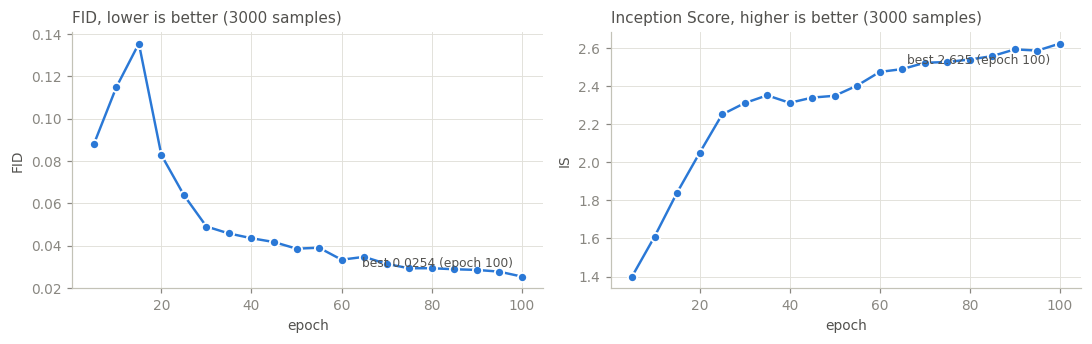

In [19]:
ev = np.array(history["eval_epoch"])
fid_hist, is_hist = np.array(history["fid"]), np.array(history["is"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
marker = dict(marker="o", markersize=6, markeredgecolor="white", markeredgewidth=1.2)
ax1.plot(ev, fid_hist, color=COLOR_G, **marker)
best = int(np.argmin(fid_hist))
label_point(ax1, ev[best], fid_hist[best], f"best {fid_hist[best]:.4f} (epoch {ev[best]})", above=True)
ax1.set_title(f"FID, lower is better ({EVAL_SAMPLES} samples)")
ax1.set_xlabel("epoch")
ax1.set_ylabel("FID")

ax2.plot(ev, is_hist, color=COLOR_G, **marker)
best = int(np.argmax(is_hist))
label_point(ax2, ev[best], is_hist[best], f"best {is_hist[best]:.3f} (epoch {ev[best]})", above=False)
ax2.set_title(f"Inception Score, higher is better ({EVAL_SAMPLES} samples)")
ax2.set_xlabel("epoch")
ax2.set_ylabel("IS")

fig.tight_layout()
save_figure(fig, "fid_is_during_training")
plt.show()

### Real vs. generated paintings

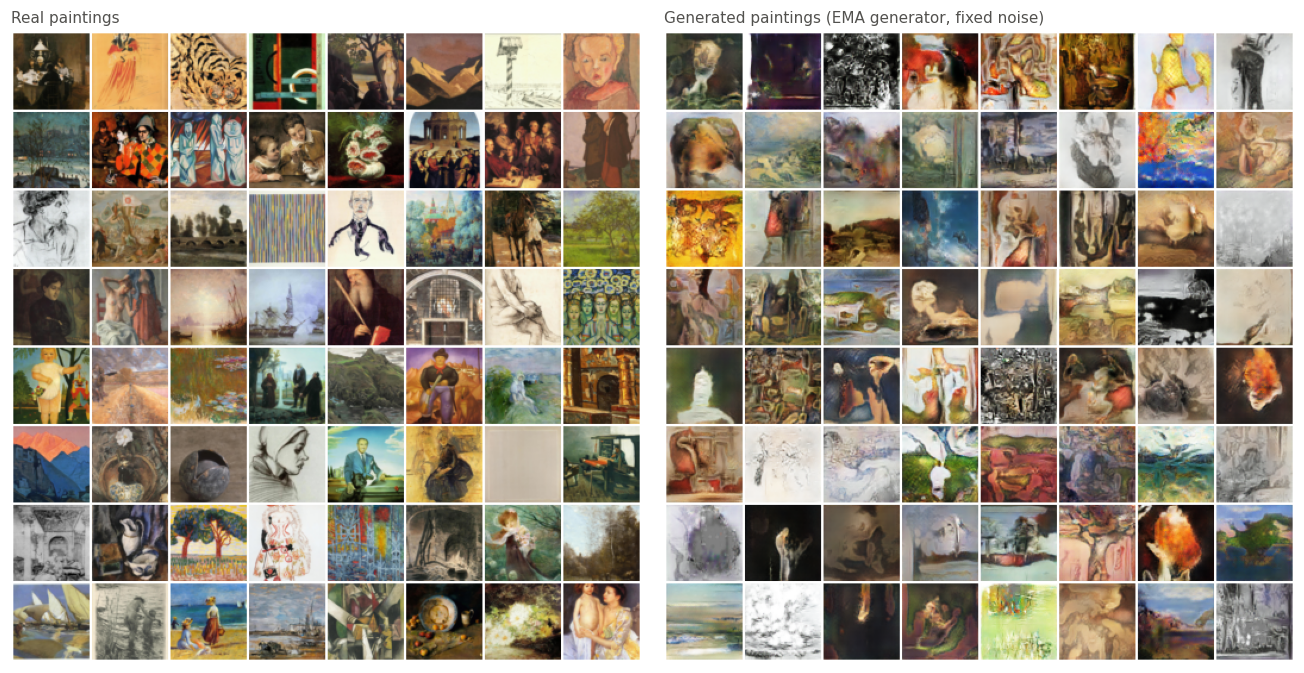

In [20]:
real_batch = next(iter(GPUImageLoader(all_images, 64, shuffle=True)))[0]
fake_batch = sample(netG_ema.generator, fixed_noise)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
ax1.imshow(grid_image(real_batch))
ax1.set_title("Real paintings")
ax1.axis("off")
ax2.imshow(grid_image(fake_batch))
ax2.set_title("Generated paintings (EMA generator, fixed noise)")
ax2.axis("off")
fig.tight_layout()
save_figure(fig, "real_vs_generated")
plt.show()

### Training progression

Samples from the same 10 fixed latent vectors at several epochs.

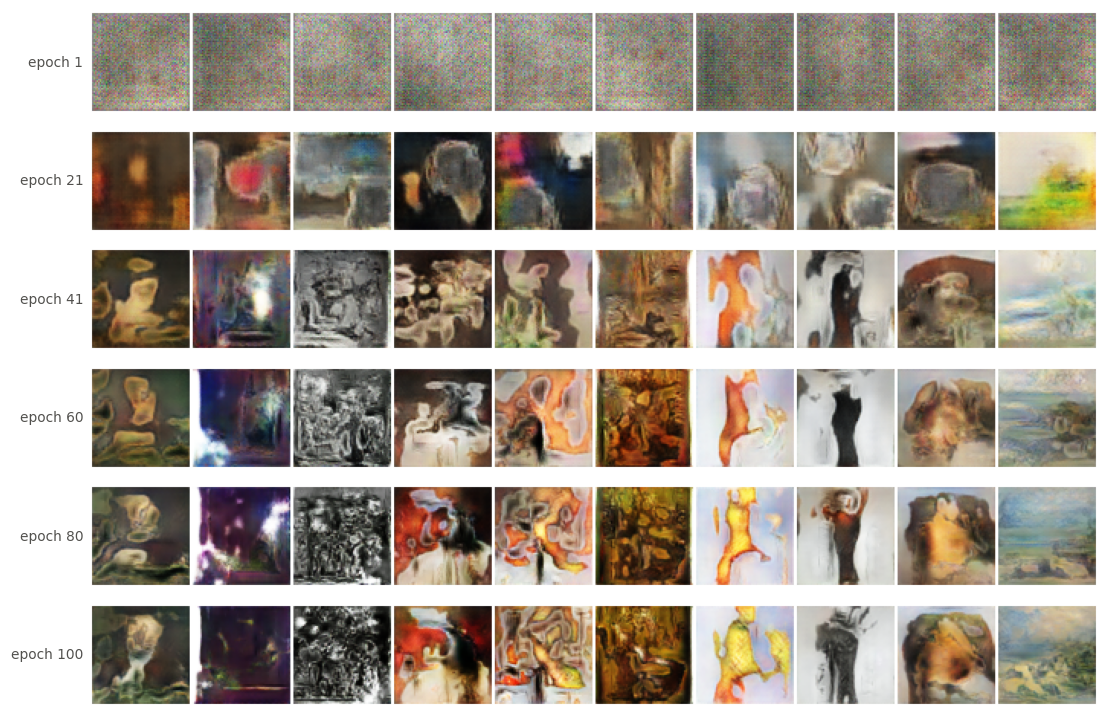

In [21]:
picks = np.unique(np.linspace(0, len(snapshots) - 1, min(6, len(snapshots))).round().astype(int))
fig, axes = plt.subplots(len(picks), 1, figsize=(10, 1.1 * len(picks)), squeeze=False)
for ax, i in zip(axes[:, 0], picks):
    epoch, imgs = snapshots[i]
    ax.imshow(grid_image(imgs[:10], nrow=10))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.set_ylabel(f"epoch {epoch}", rotation=0, ha="right", va="center", color=INK)
fig.tight_layout()
save_figure(fig, "training_progression")
plt.show()

## 10. Final evaluation

The final numbers use `FINAL_EVAL_SAMPLES` generated images against the same number of real images, for both the raw
generator and its EMA. Two **reference values** from real data put the scores in context:

* *FID real vs. real*: FID between two disjoint random sets of real paintings. It is the floor a perfect generator would
  reach at this sample size.
* *IS real*: Inception Score of real paintings.

In [22]:
torch.manual_seed(SEED)
t0 = time.time()
results = {
    "Generator (EMA)": evaluate(generator_sampler(netG_ema.generator), final_dataloader),
    "Generator (raw)": evaluate(generator_sampler(netG), final_dataloader),
    "Real data (reference)": evaluate(real_sampler(eval_real_b), final_dataloader),
}
print(f"{FINAL_EVAL_SAMPLES} generated vs {FINAL_EVAL_SAMPLES} real images ({time.time() - t0:.0f}s)\n")
print(f"{'':24s}{'FID (lower=better)':>20s}{'IS (higher=better)':>20s}")
for name, (fid_v, is_v) in results.items():
    print(f"{name:24s}{fid_v:20.4f}{is_v:20.3f}")

best_name = min(("Generator (EMA)", "Generator (raw)"), key=lambda k: results[k][0])
best_G = netG_ema.generator if best_name == "Generator (EMA)" else netG
print(f"\nUsing {best_name} (lower FID) for the samples below.")

with open(OUT_DIR / "metrics.json", "w") as f:
    json.dump({"num_samples": FINAL_EVAL_SAMPLES,
               "final": {k: {"fid": v[0], "is": v[1]} for k, v in results.items()},
               "during_training": {"epoch": history["eval_epoch"], "fid": history["fid"], "is": history["is"],
                                   "num_samples": EVAL_SAMPLES}}, f, indent=2)

10000 generated vs 10000 real images (129s)

                          FID (lower=better)  IS (higher=better)
Generator (EMA)                       0.0240               2.624
Generator (raw)                       0.0264               2.591
Real data (reference)                 0.0037               3.661

Using Generator (EMA) (lower FID) for the samples below.


## 11. Generate paintings

Fresh random latent vectors go through the trained generator. Grids are saved at native resolution as PNG
(`generated_samples.png`, plus 256 samples in `generated_samples_256.png`).

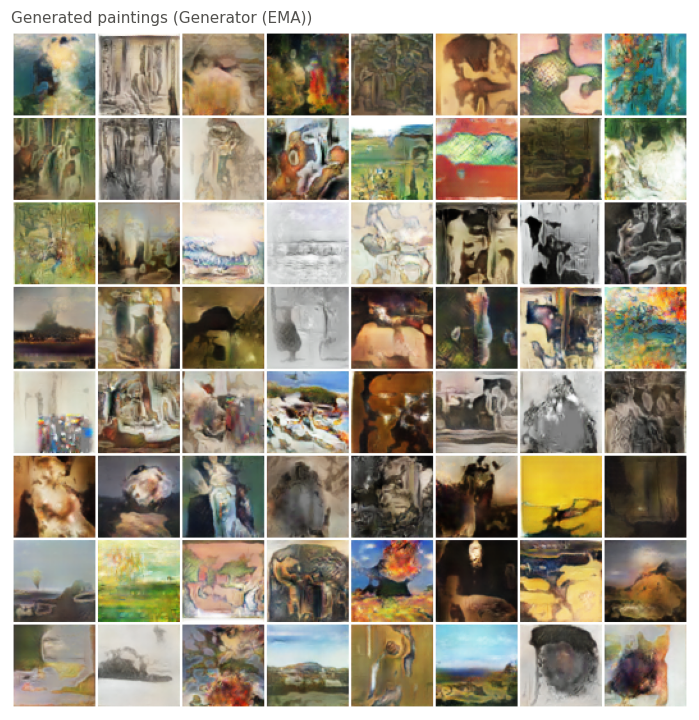

In [23]:
torch.manual_seed(SEED + 1)
samples = generate(best_G, 256)
Image.fromarray(grid_image(samples[:64], nrow=8)).save(OUT_DIR / "generated_samples.png")
Image.fromarray(grid_image(samples, nrow=16)).save(OUT_DIR / "generated_samples_256.png")

fig, ax = plt.subplots(figsize=(8, 8))
ax.imshow(grid_image(samples[:64], nrow=8))
ax.set_title(f"Generated paintings ({best_name})")
ax.axis("off")
plt.show()

### Latent space interpolation

Each row walks along a spherical interpolation between two random latent vectors. Smooth transitions suggest the
generator learned a continuous latent space rather than memorising individual paintings.

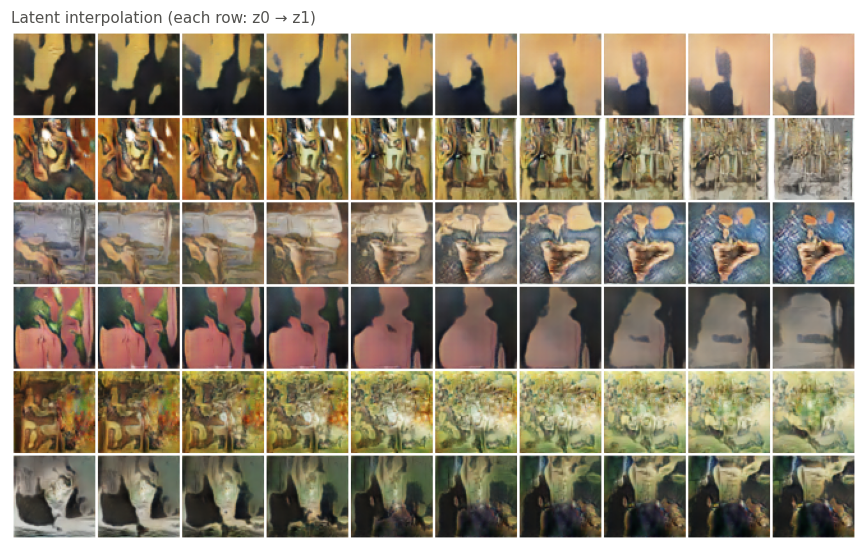

In [24]:
def slerp(z0, z1, t):
    omega = torch.acos((z0.flatten() / z0.norm() @ (z1.flatten() / z1.norm())).clamp(-1, 1))
    return (torch.sin((1 - t) * omega) * z0 + torch.sin(t * omega) * z1) / torch.sin(omega)


torch.manual_seed(SEED + 2)
n_rows, n_steps = 6, 10
z_path = []
for _ in range(n_rows):
    z0, z1 = torch.randn(2, LATENT_DIM, 1, 1, device=device)
    z_path += [slerp(z0, z1, t) for t in torch.linspace(0, 1, n_steps, device=device)]
interp = sample(best_G, torch.stack(z_path))

img = grid_image(interp, nrow=n_steps)
Image.fromarray(img).save(OUT_DIR / "latent_interpolation.png")
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(img)
ax.set_title("Latent interpolation (each row: z0 → z1)")
ax.axis("off")
plt.show()

## Outputs for the report

| Report item | File in `outputs/` |
|---|---|
| 1) Hyperparameters | `hparams.json` (and the table printed in section 2) |
| 2) Training loss curves | `loss_curves.pdf/.png` |
| 3) Inception Score and FID | `metrics.json`, `fid_is_during_training.pdf/.png`, table in section 10 |
| 4) Generated images | `generated_samples.png`, `generated_samples_256.png`, `real_vs_generated.png`, `training_progression.png`, `latent_interpolation.png` |